# Tutorial 08b: CNNs for citywide taxi-flow prediction

TaxiBJ21 divides Beijing into a 32 × 32 grid. Every grid cell is one urban region (one pixel), and every half-hour has two channels: **inflow**, the number of trips entering the region, and **outflow**, the number of trips leaving it. The forecasting problem is to predict the next citywide inflow and outflow maps.

Unlike MNIST, nearby pixels represent nearby urban areas and the output is continuous rather than categorical. A useful model must learn both temporal regularities—recent conditions, yesterday and last week—and spatial relations between neighbouring regions.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `08 Convolutional neural networks`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "08 Convolutional neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/08 Convolutional neural networks


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch


Note: you may need to restart the kernel to use updated packages.


In [4]:
DATA_FILE="taxibj21_small.npz"

## Open the notebook

In [5]:
from pathlib import Path
if not Path(DATA_FILE).exists():
    !git clone -q https://github.com/JinTaoKe/AI-Code.git
    %cd "AI-Code/08 Convolutional neural networks"

In [6]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LinearRegression, Ridge
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


## 1. Inspect the four-dimensional array

The dimensions are time × channel × row × column. Channel 0 is inflow and channel 1 is outflow. The compact TaxiBJ21 source is distributed as relative flow intensity from 0 to 1 and does not include the inverse-scaling parameters needed to recover vehicle counts. We therefore label it honestly as relative intensity rather than treating it as a raw count. Thus `flow[t, 0, r, c]` is the relative inflow intensity of grid region $(r,c)$ during half-hour interval $t$.

flow array: (2400, 2, 32, 32) = (time, channel, row, column)
dtype: float32
stored value range: (0.0, 1.0) = relative intensity from 0 to 1
one frame: (2, 32, 32) = (inflow/outflow, 32 rows, 32 columns)
Raw vehicle counts cannot be reconstructed because the source file has no inverse-scaling metadata.


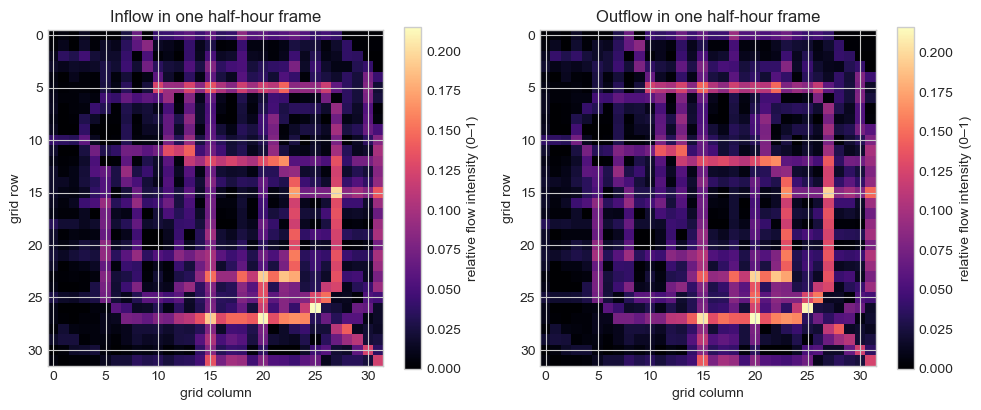

In [7]:
flow = np.load(DATA_FILE)["flow"]
print("flow array:", flow.shape, "= (time, channel, row, column)")
print("dtype:", flow.dtype)
print("stored value range:", (flow.min(), flow.max()), "= relative intensity from 0 to 1")
print("one frame:", flow[0].shape, "= (inflow/outflow, 32 rows, 32 columns)")
print("Raw vehicle counts cannot be reconstructed because the source file has no inverse-scaling metadata.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for channel, ax, title in zip(range(2), axes, ["Inflow", "Outflow"]):
    image = ax.imshow(flow[100, channel], cmap="magma")
    ax.set_title(f"{title} in one half-hour frame")
    ax.set_xlabel("grid column")
    ax.set_ylabel("grid row")
    fig.colorbar(image, ax=ax, label="relative flow intensity (0–1)")
plt.tight_layout()

## 2. Visualize spatial and temporal structure

The mean maps identify consistently active regions. The citywide totals reveal repeated peaks over time.

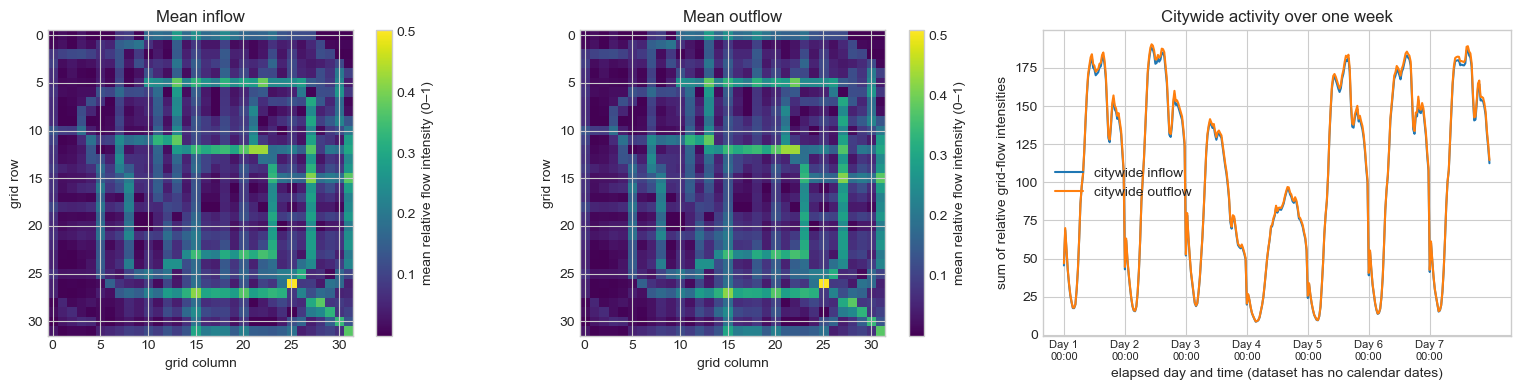

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for channel, ax, title in zip(range(2), axes[:2], ["Mean inflow", "Mean outflow"]):
    image = ax.imshow(flow[:, channel].mean(axis=0), cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("grid column")
    ax.set_ylabel("grid row")
    fig.colorbar(image, ax=ax, label="mean relative flow intensity (0–1)")

one_week = 7 * 48
half_hour_steps = np.arange(one_week)
axes[2].plot(
    half_hour_steps,
    flow[:one_week, 0].sum(axis=(1, 2)),
    label="citywide inflow",
)
axes[2].plot(
    half_hour_steps,
    flow[:one_week, 1].sum(axis=(1, 2)),
    label="citywide outflow",
)
axes[2].set_title("Citywide activity over one week")
tick_steps = np.arange(0, one_week, 48)  # once per day
tick_labels = [
    f"Day {step // 48 + 1}\n{(step % 48) // 2:02d}:{(step % 2) * 30:02d}"
    for step in tick_steps
]
axes[2].set_xticks(tick_steps, tick_labels)
axes[2].tick_params(axis="x", labelsize=8)
axes[2].set_xlabel("elapsed day and time (dataset has no calendar dates)")
axes[2].set_ylabel("sum of relative grid-flow intensities")
axes[2].legend()
plt.tight_layout()

## 3. Build closeness, daily-period and weekly-trend features

Following the temporal ideas in [ST-ResNet](https://ojs.aaai.org/index.php/AAAI/article/view/10735), each target uses three kinds of evidence:

- **closeness:** the previous four half-hour frames, covering the last two hours;
- **daily period:** the same half-hour yesterday, lag 48;
- **weekly trend:** the same half-hour one week ago, lag 336.

Each lag contributes both inflow and outflow, so the CNN input has $6\times2=12$ channels. Linear and Ridge baselines use exactly these 12 values from the target grid cell itself. They do not see neighbouring cells. The CNN receives the same features as 12 complete maps and can additionally learn spatial patterns with convolution.

In [9]:
def make_flow_examples(flow, lags):
    inputs = []
    targets = []
    target_times = []
    start = max(lags)

    for target_time in range(start, len(flow)):
        lagged_maps = [flow[target_time - lag] for lag in lags]
        inputs.append(np.concatenate(lagged_maps, axis=0))
        targets.append(flow[target_time])
        target_times.append(target_time)

    X = np.asarray(inputs, dtype="float32")
    y = np.asarray(targets, dtype="float32")
    return X, y, np.asarray(target_times)


class SpatialResidualCNN(nn.Module):
    def __init__(self, in_channels, hidden=32):
        super().__init__()
        self.temporal_projection = nn.Conv2d(
            in_channels,
            2,
            kernel_size=1,
        )
        self.spatial_correction = nn.Sequential(
            nn.Conv2d(in_channels, hidden, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, 2, kernel_size=3, padding=1),
        )
        final_layer = self.spatial_correction[-1]
        nn.init.zeros_(final_layer.weight)
        nn.init.zeros_(final_layer.bias)

    def forward(self, x):
        temporal_prediction = self.temporal_projection(x)
        spatial_adjustment = self.spatial_correction(x)
        return temporal_prediction + spatial_adjustment


def validation_loss(model, valid_loader, loss_fn):
    model.eval()
    total = 0
    with torch.no_grad():
        for xb, yb in valid_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            total += loss_fn(model(xb), yb).item() * len(xb)
    return total / len(valid_loader.dataset)


def fit_flow(model, train_loader, valid_loader, epochs=15, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train": [], "valid": []}
    best_loss = validation_loss(model, valid_loader, loss_fn)
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        train_total = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_total += loss.item() * len(xb)

        train_loss = train_total / len(train_loader.dataset)
        valid_loss = validation_loss(model, valid_loader, loss_fn)
        history["train"].append(train_loss)
        history["valid"].append(valid_loss)
        if valid_loss < best_loss:
            best_loss = valid_loss
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"epoch {epoch + 1:02d} | "
            f"train MSE {train_loss:.5f} | validation MSE {valid_loss:.5f} "
            f"[relative intensity²]"
        )

    model.load_state_dict(best_state)
    return history


def flow_predict(model, X):
    model.eval()
    outputs = []
    with torch.no_grad():
        loader = DataLoader(TensorDataset(torch.tensor(X)), batch_size=64)
        for (xb,) in loader:
            outputs.append(model(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(outputs)

In [10]:
LAGS = [1, 2, 3, 4, 48, 336]
FEATURE_NAMES = [
    "30 min ago",
    "1 hour ago",
    "1.5 hours ago",
    "2 hours ago",
    "same time yesterday",
    "same time last week",
]

X, y, target_time = make_flow_examples(flow, LAGS)
train_mask = target_time < 1600
valid_mask = (target_time >= 1600) & (target_time < 2000)
test_mask = target_time >= 2000

X_train = X[train_mask]
y_train = y[train_mask]
X_valid = X[valid_mask]
y_valid = y[valid_mask]
X_test = X[test_mask]
y_test = y[test_mask]

feature_table = pd.DataFrame({
    "temporal role": ["closeness"] * 4 + ["daily period", "weekly trend"],
    "source frame": FEATURE_NAMES,
    "lag (half-hours)": LAGS,
    "CNN channels": ["inflow + outflow"] * len(LAGS),
})
display(feature_table)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("X dimensions: samples × 12 lagged flow maps × 32 rows × 32 columns.")
print("y dimensions: samples × 2 target maps (inflow/outflow) × 32 × 32.")

train_dataset = TensorDataset(
    torch.tensor(X_train),
    torch.tensor(y_train),
)
valid_dataset = TensorDataset(
    torch.tensor(X_valid),
    torch.tensor(y_valid),
)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=64)

,temporal role,source frame,lag (half-hours),CNN channels
0,closeness,30 min ago,1,inflow + outflow
1,closeness,1 hour ago,2,inflow + outflow
2,closeness,1.5 hours ago,3,inflow + outflow
3,closeness,2 hours ago,4,inflow + outflow
4,daily period,same time yesterday,48,inflow + outflow
5,weekly trend,same time last week,336,inflow + outflow


X_train: (1264, 12, 32, 32) y_train: (1264, 2, 32, 32)
X_valid: (400, 12, 32, 32) y_valid: (400, 2, 32, 32)
X_test : (400, 12, 32, 32) y_test : (400, 2, 32, 32)
X dimensions: samples × 12 lagged flow maps × 32 rows × 32 columns.
y dimensions: samples × 2 target maps (inflow/outflow) × 32 × 32.


## 4. Non-spatial regression baselines and a residual CNN

Linear Regression and Ridge treat every grid cell as an independent regression example. Their 12 predictors are that cell's own inflow and outflow at the six selected lags; they have no neighbouring-grid features.

The CNN receives the same 12 channels as complete 32 × 32 maps. Its 1 × 1 temporal branch is initialized with the selected Ridge coefficients, so it begins with the same non-spatial prediction. A 3 × 3 convolutional branch then learns a spatial correction from neighbouring regions. This isolates the value added by spatial information and prevents the CNN from collapsing to a near-zero map.

In [11]:
def grid_regression_arrays(X, y):
    X_grid = X.transpose(0, 2, 3, 1).reshape(-1, X.shape[1])
    y_grid = y.transpose(0, 2, 3, 1).reshape(-1, 2)
    return X_grid, y_grid


X_train_grid, y_train_grid = grid_regression_arrays(X_train, y_train)
X_valid_grid, y_valid_grid = grid_regression_arrays(X_valid, y_valid)
print("Linear/Ridge input:", X_train_grid.shape, "= (N × grid cells, lag features)")
print("CNN input:", X_train.shape, "= (N, channels, rows, columns)")
print("Both predict inflow and outflow for every grid cell.")

linear_model = LinearRegression()
linear_model.fit(X_train_grid, y_train_grid)

ridge_candidates = {}
for alpha in [0.1, 1.0, 10.0]:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_grid, y_train_grid)
    valid_prediction = ridge_model.predict(X_valid_grid)
    valid_mae = np.abs(y_valid_grid - valid_prediction).mean()
    ridge_candidates[alpha] = {
        "model": ridge_model,
        "validation MAE": valid_mae,
    }

ridge_validation = pd.DataFrame([
    {"alpha": alpha, "validation MAE": result["validation MAE"]}
    for alpha, result in ridge_candidates.items()
])
display(ridge_validation.round(5))
best_alpha = ridge_validation.loc[
    ridge_validation["validation MAE"].idxmin(),
    "alpha",
]
ridge_model = ridge_candidates[best_alpha]["model"]
print("selected Ridge alpha:", best_alpha)

model = SpatialResidualCNN(
    in_channels=X_train.shape[1],
    hidden=32,
).to(DEVICE)
with torch.no_grad():
    ridge_weights = torch.tensor(ridge_model.coef_, dtype=torch.float32)
    ridge_bias = torch.tensor(ridge_model.intercept_, dtype=torch.float32)
    model.temporal_projection.weight.copy_(ridge_weights[:, :, None, None])
    model.temporal_projection.bias.copy_(ridge_bias)

for parameter in model.temporal_projection.parameters():
    parameter.requires_grad = False
print(model)
with torch.no_grad():
    demo_output = model(torch.tensor(X_train[:4]).to(DEVICE))
print("CNN input shape :", X_train[:4].shape)
print("CNN output shape:", tuple(demo_output.shape))
n_trainable = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)
print("trainable parameters in spatial branch:", n_trainable)

Linear/Ridge input: (1294336, 12) = (N × grid cells, lag features)
CNN input: (1264, 12, 32, 32) = (N, channels, rows, columns)
Both predict inflow and outflow for every grid cell.


,alpha,validation MAE
0,0.1,0.01128
1,1.0,0.01128
2,10.0,0.01130


selected Ridge alpha: 1.0
SpatialResidualCNN(
  (temporal_projection): Conv2d(12, 2, kernel_size=(1, 1), stride=(1, 1))
  (spatial_correction): Sequential(
    (0): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 2, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)
CNN input shape : (4, 12, 32, 32)
CNN output shape: (4, 2, 32, 32)
trainable parameters in spatial branch: 13314


## 5. Train the CNN with validation-based stopping

Before training, the frozen 1 × 1 branch exactly reproduces Ridge at every grid cell. The zero-initialized spatial branch initially adds nothing. Training updates only the 3 × 3 spatial branch, and the best validation epoch—including the initial Ridge-equivalent state—is retained before test evaluation.


epoch 01 | train MSE 0.00055 | validation MSE 0.00036 [relative intensity²]
epoch 02 | train MSE 0.00055 | validation MSE 0.00035 [relative intensity²]
epoch 03 | train MSE 0.00054 | validation MSE 0.00033 [relative intensity²]
epoch 04 | train MSE 0.00054 | validation MSE 0.00036 [relative intensity²]
epoch 05 | train MSE 0.00054 | validation MSE 0.00036 [relative intensity²]
epoch 06 | train MSE 0.00053 | validation MSE 0.00033 [relative intensity²]
epoch 07 | train MSE 0.00053 | validation MSE 0.00035 [relative intensity²]
epoch 08 | train MSE 0.00051 | validation MSE 0.00035 [relative intensity²]
epoch 09 | train MSE 0.00050 | validation MSE 0.00029 [relative intensity²]
epoch 10 | train MSE 0.00050 | validation MSE 0.00035 [relative intensity²]
epoch 11 | train MSE 0.00049 | validation MSE 0.00030 [relative intensity²]
epoch 12 | train MSE 0.00049 | validation MSE 0.00031 [relative intensity²]
epoch 13 | train MSE 0.00048 | validation MSE 0.00031 [relative intensity²]
epoch 14 | t

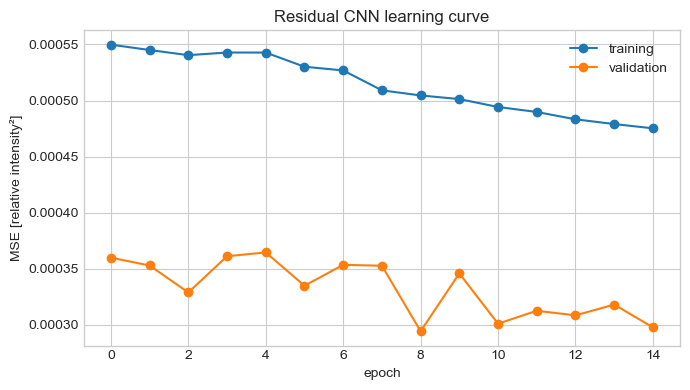

In [12]:
history = fit_flow(
    model,
    train_loader,
    valid_loader,
    epochs=15,
    lr=1e-3,
)
plt.figure(figsize=(7, 4))
plt.plot(history["train"], marker="o", label="training")
plt.plot(history["valid"], marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE [relative intensity²]")
plt.title("Residual CNN learning curve")
plt.legend()
plt.tight_layout()
plt.show()

def flow_scores(name, prediction, target):
    errors = target - prediction
    return {
        "model": name,
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    }


## 6. Freeze the forecaster

Ridge alpha, CNN architecture and CNN stopping epoch are now fixed by validation data. Linear Regression has no tuned hyperparameter. All frozen methods will be compared on the test period once.


In [13]:
print("Linear, Ridge and CNN settings are frozen. Proceeding to the final test comparison.")


Linear, Ridge and CNN settings are frozen. Proceeding to the final test comparison.


## 7. Final test comparison and spatial residual maps

Evaluate four frozen methods on test data once:

1. latest-frame persistence;
2. Linear Regression using only the target cell's 12 lagged values;
3. Ridge using the same non-spatial features; and
4. the residual CNN using the 12 full spatial maps.

The final maps use a busy test frame so that underprediction and spatial displacement are easy to see.


MAE and RMSE below use the dataset's 0–1 relative-intensity scale.


,model,MAE,RMSE
0,Latest frame,0.01072,0.01722
1,Linear regression,0.00970,0.01661
2,Ridge regression,0.00884,0.01460
3,Spatial residual CNN,0.00880,0.01446


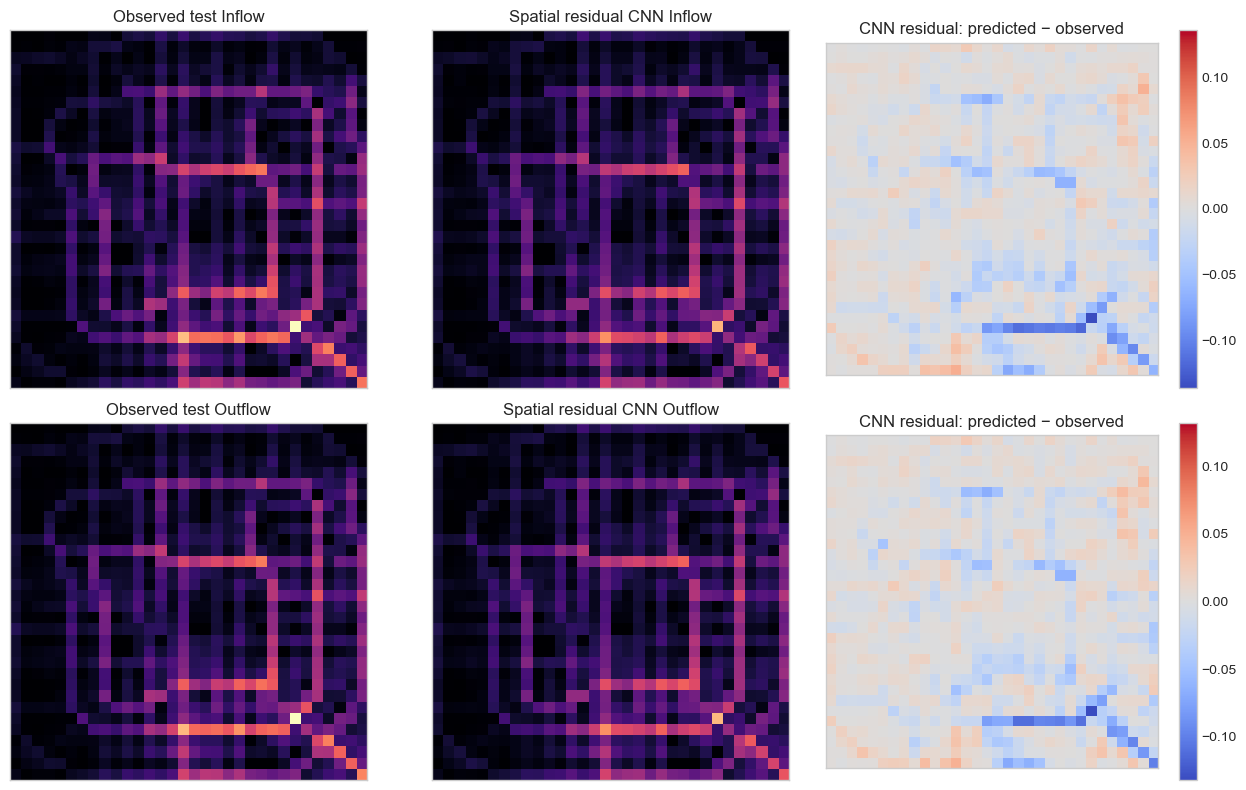

In [14]:
def grid_predictions_to_maps(prediction, n_samples):
    maps = prediction.reshape(n_samples, 32, 32, 2)
    return maps.transpose(0, 3, 1, 2)


X_test_grid, _ = grid_regression_arrays(X_test, y_test)
test_latest = X_test[:, 0:2]
test_linear = grid_predictions_to_maps(
    linear_model.predict(X_test_grid),
    n_samples=len(X_test),
)
test_ridge = grid_predictions_to_maps(
    ridge_model.predict(X_test_grid),
    n_samples=len(X_test),
)
test_cnn = flow_predict(model, X_test)

test_results = pd.DataFrame([
    flow_scores("Latest frame", test_latest, y_test),
    flow_scores("Linear regression", test_linear, y_test),
    flow_scores("Ridge regression", test_ridge, y_test),
    flow_scores("Spatial residual CNN", test_cnn, y_test),
])
print("MAE and RMSE below use the dataset's 0–1 relative-intensity scale.")
display(test_results.round(5))

busy_frame = int(np.argmax(y_test[:, 0].sum(axis=(1, 2))))
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for channel, channel_name in enumerate(["Inflow", "Outflow"]):
    vmax = y_test[busy_frame, channel].max()
    axes[channel, 0].imshow(
        y_test[busy_frame, channel],
        cmap="magma",
        vmin=0,
        vmax=vmax,
    )
    axes[channel, 0].set_title(f"Observed test {channel_name}")
    axes[channel, 1].imshow(
        test_cnn[busy_frame, channel],
        cmap="magma",
        vmin=0,
        vmax=vmax,
    )
    axes[channel, 1].set_title(f"Spatial residual CNN {channel_name}")

    residual = test_cnn[busy_frame, channel] - y_test[busy_frame, channel]
    limit = np.abs(residual).max()
    residual_image = axes[channel, 2].imshow(
        residual,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
    )
    axes[channel, 2].set_title("CNN residual: predicted − observed")
    fig.colorbar(residual_image, ax=axes[channel, 2])

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()


## What to remember

- A traffic grid is an image-like representation with domain-specific channels.
- Closeness, daily period and weekly trend become explicit lagged feature maps.
- A fully convolutional network preserves spatial layout from input to output.
- Linear and Ridge baselines use each cell's own temporal features but no spatial neighbours.
- A residual CNN starts from persistence and learns spatial-temporal corrections.
- Use validation data for Ridge alpha and CNN stopping, then compare all frozen models once on test data.